# 02. Position from the IMU, alone and with sparse fixes

The accelerometer measures specific force, which is the vehicle's acceleration minus gravity, in the body frame. To get position, each sample is rotated into the world frame with the gyro orientation, gravity is added back, and the result is integrated twice.

Integrating twice is the problem. A constant acceleration error $\delta a$ produces a position error of $\tfrac{1}{2}\,\delta a\,t^2$. An attitude error of only 1 degree tilts 9.81 m/s² of gravity into the horizontal by 0.17 m/s², which by itself gives about 34 m of error after 20 s. In practice an IMU needs a second sensor to bound position drift.

This notebook first shows IMU-only dead reckoning, then fuses the IMU with a position fix once per second in an error-state Kalman filter (EKF). The fixes are taken from the ground truth and stand in for a GPS receiver, a motion-capture system, or a visual odometry front end.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path.cwd().parent))
from imu_tracking import data, evaluation, integration, plots

# Folder holding the MVSEC bags. Change this to wherever you downloaded them.
DATA_DIR = Path.home() / "Developer/Projects/event-vision-toolkit/data/raw/mvsec"
SEQUENCE_NAME = "indoor_flying4"
CALIBRATION_PATH = Path("../calibration/camchain_imucam_indoor_flying.yaml")
CACHE_PATH = Path(f"../data/{SEQUENCE_NAME}.npz")
FIGURE_DIR = Path("../figures")

# The hexacopter rests on the floor for about 3.5 s before the propellers spin up
STATIC_DURATION = 3.0

FIGURE_DIR.mkdir(exist_ok=True)
plots.use_paper_style()

from imu_tracking import ekf

In [2]:
sequence = data.load_sequence(
    DATA_DIR / f"{SEQUENCE_NAME}_data.bag",
    DATA_DIR / f"{SEQUENCE_NAME}_gt.bag",
    CACHE_PATH,
)
camera_from_imu_rotation, imu_origin_in_camera = data.load_imu_to_camera_extrinsics(CALIBRATION_PATH)

imu_time = sequence["imu_time"] - sequence["imu_time"][0]
accel = sequence["accel"]
gyro = sequence["gyro"]

imu_rate = 1 / np.median(np.diff(imu_time))
ground_truth_rate = 1 / np.median(np.diff(sequence["ground_truth_time"]))
print(f"IMU samples:          {len(imu_time)} at {imu_rate:.0f} Hz over {imu_time[-1]:.1f} s")
print(f"Ground-truth poses:   {len(sequence['ground_truth_time'])} at {ground_truth_rate:.0f} Hz")

IMU samples:          19862 at 1001 Hz over 19.8 s
Ground-truth poses:   1697 at 91 Hz


In [3]:
static_result = data.estimate_static_biases(sequence, STATIC_DURATION)
gyro_bias = static_result["gyro_bias"]
accel_bias = static_result["accel_bias"]

world_from_first_camera = data.build_world_frame(static_result["up_direction_in_imu"], camera_from_imu_rotation)
camera_tilt = np.degrees(np.arccos(np.dot(world_from_first_camera[2], [0.0, -1.0, 0.0])))

time_offset = data.estimate_ground_truth_time_offset(sequence, camera_from_imu_rotation)
ground_truth_time, ground_truth_positions, ground_truth_rotations = data.ground_truth_imu_poses(
    sequence, world_from_first_camera, camera_from_imu_rotation, imu_origin_in_camera, time_offset
)
ground_truth_time = ground_truth_time - sequence["imu_time"][0]

# MVSEC ground truth starts at the identity, so the first IMU pose follows from the frame choice alone
initial_rotation = world_from_first_camera @ camera_from_imu_rotation
initial_position = ground_truth_positions[0]
imu_from_body_rotation = initial_rotation.T

print(f"|accel| at rest:      {static_result['mean_accel_magnitude']:.3f} m/s^2 (gravity is 9.81)")
print(f"accel std at rest:    {np.round(static_result['accel_std_at_rest'], 3)} m/s^2")
print(f"gyro bias:            {np.round(gyro_bias, 4)} rad/s")
print(f"camera tilt at rest:  {camera_tilt:.1f} deg below horizontal")
print(f"ground-truth offset:  {time_offset * 1000:.1f} ms")

|accel| at rest:      8.771 m/s^2 (gravity is 9.81)
accel std at rest:    [0.106 0.233 0.146] m/s^2
gyro bias:            [-0.0151 -0.0224 -0.0099] rad/s
camera tilt at rest:  16.9 deg below horizontal
ground-truth offset:  -57.5 ms


## Dead reckoning

In [4]:
dead_reckoning_positions, dead_reckoning_rotations = integration.dead_reckoning(
    imu_time, accel, gyro, accel_bias, gyro_bias, initial_rotation, initial_position
)

matched_indices = evaluation.nearest_indices(imu_time, ground_truth_time)
dead_reckoning_position_error = evaluation.position_errors(dead_reckoning_positions[matched_indices], ground_truth_positions)
dead_reckoning_rotation_error = evaluation.rotation_errors_degrees(
    dead_reckoning_rotations[matched_indices], ground_truth_rotations
)

for checkpoint in [5, 7, 10, 15, 19]:
    closest = np.argmin(np.abs(ground_truth_time - checkpoint))
    print(f"t = {checkpoint:2d} s   dead-reckoning position error {dead_reckoning_position_error[closest]:6.2f} m")

t =  5 s   dead-reckoning position error   0.01 m
t =  7 s   dead-reckoning position error   0.15 m
t = 10 s   dead-reckoning position error   0.89 m
t = 15 s   dead-reckoning position error   4.35 m
t = 19 s   dead-reckoning position error  11.06 m


## Error-state Kalman filter with 1 Hz position fixes

The filter keeps the full IMU integration as its prediction step. It also tracks a 15-number error state (position, velocity, attitude, accelerometer bias, gyro bias) and its covariance. When a position fix arrives, the difference between the fix and the predicted position corrects position directly. The covariance spreads the correction to velocity, attitude, and the biases, because those are the states that caused the position to drift.

The accelerometer noise is set to 3 m/s². That is much larger than the 0.25 m/s² measured at rest, because six spinning propellers shake the sensor in flight. With the at-rest value the filter trusts the accelerometer too much and pushes the correction into attitude, which raised the maximum rotation error from about 2.5 to 7.2 degrees in tests.

In [5]:
FIX_RATE_HZ = 1.0

EKF_NOISE = {
    "accel_std": 3.0,                # m/s^2, flight vibration dominates
    "gyro_std": 0.001,               # rad/s
    "accel_bias_walk": 1e-3,         # m/s^2 per sqrt(s)
    "gyro_bias_walk": 1e-4,          # rad/s per sqrt(s)
    "fix_position_std": 0.02,        # m
    "initial_position_std": 0.01,
    "initial_velocity_std": 0.01,
    "initial_attitude_std": 0.01,    # rad
    "initial_accel_bias_std": 0.1,
    "initial_gyro_bias_std": 0.001,
}

# One fix every second, taken from the ground-truth pose closest to each whole second
requested_fix_times = np.arange(1 / FIX_RATE_HZ, ground_truth_time[-1], 1 / FIX_RATE_HZ)
fix_indices = evaluation.nearest_indices(ground_truth_time, requested_fix_times)
fix_time = ground_truth_time[fix_indices]
fix_position = ground_truth_positions[fix_indices]

ekf_result = ekf.run_position_aided_ekf(
    imu_time, accel, gyro, fix_time, fix_position,
    initial_rotation, initial_position, accel_bias, gyro_bias,
    EKF_NOISE,
)

ekf_position_error = evaluation.position_errors(ekf_result["positions"][matched_indices], ground_truth_positions)
ekf_rotation_error = evaluation.rotation_errors_degrees(ekf_result["rotations"][matched_indices], ground_truth_rotations)

print(f"{len(fix_time)} position fixes used\n")
evaluation.summarize("IMU only (dead reckoning)", dead_reckoning_position_error, dead_reckoning_rotation_error)
evaluation.summarize("EKF (IMU + 1 Hz fix)", ekf_position_error, ekf_rotation_error)

19 position fixes used

IMU only (dead reckoning)    position RMSE  4.415 m | max  13.19 m | rotation mean  0.26 deg | max  0.96 deg
EKF (IMU + 1 Hz fix)         position RMSE  0.066 m | max   0.25 m | rotation mean  0.48 deg | max  2.48 deg


## Figures

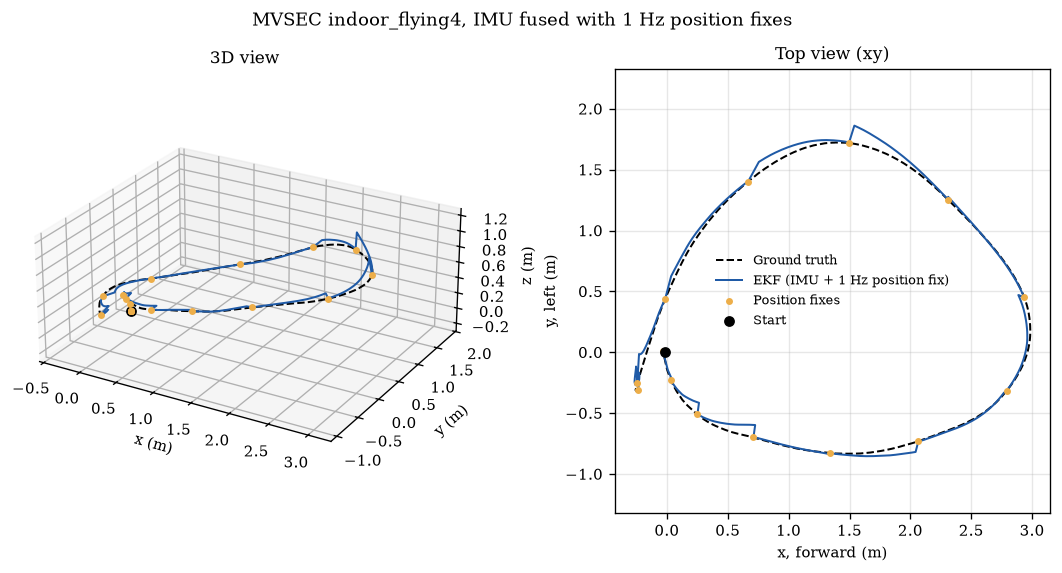

In [6]:
figure = plots.plot_trajectory(
    ground_truth_positions,
    {"EKF (IMU + 1 Hz position fix)": ekf_result["positions"]},
    fix_positions=fix_position,
    title="MVSEC indoor_flying4, IMU fused with 1 Hz position fixes",
)
figure.savefig(FIGURE_DIR / "trajectory_ekf.png")
plt.show()

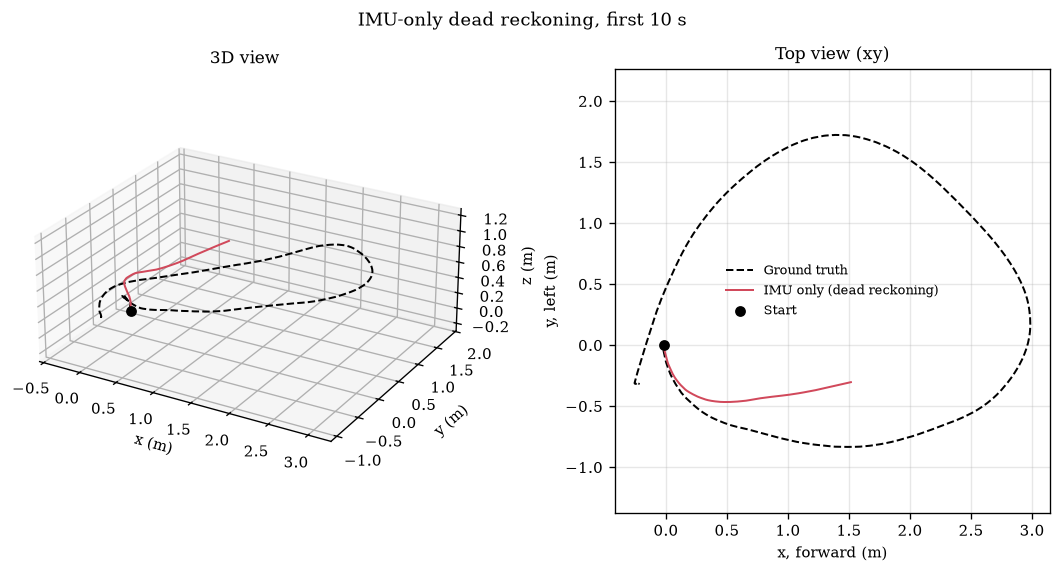

In [7]:
figure = plots.plot_trajectory(
    ground_truth_positions,
    {"IMU only (dead reckoning)": dead_reckoning_positions[: np.searchsorted(imu_time, 10.0)]},
    title="IMU-only dead reckoning, first 10 s",
)
figure.savefig(FIGURE_DIR / "trajectory_dead_reckoning.png")
plt.show()

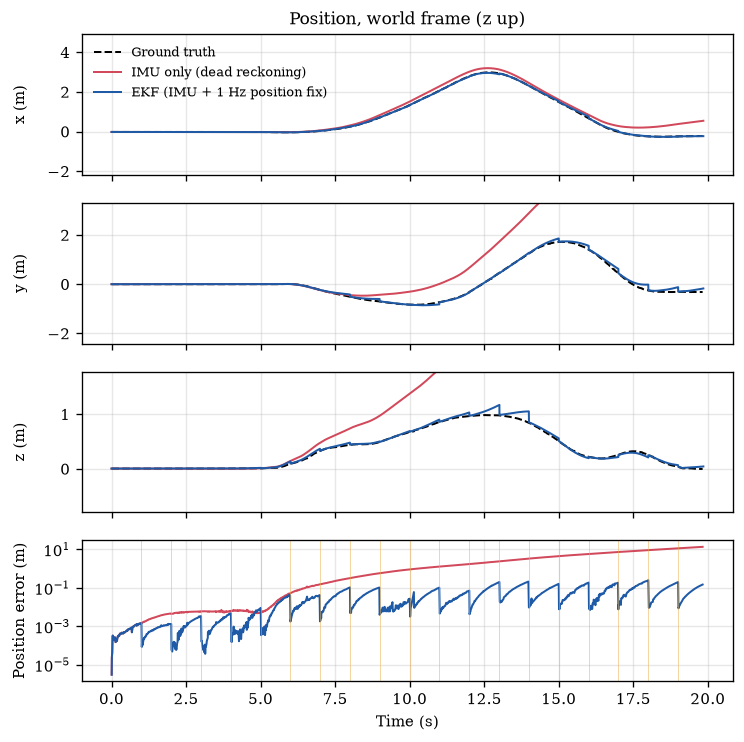

In [8]:
position_estimates = {
    "IMU only (dead reckoning)": (imu_time, dead_reckoning_positions, dead_reckoning_position_error),
    "EKF (IMU + 1 Hz position fix)": (imu_time, ekf_result["positions"], ekf_position_error),
}
figure = plots.plot_position_components(
    ground_truth_time, ground_truth_positions, position_estimates, fix_times=fix_time, error_log_scale=True
)
figure.savefig(FIGURE_DIR / "position_components.png")
plt.show()

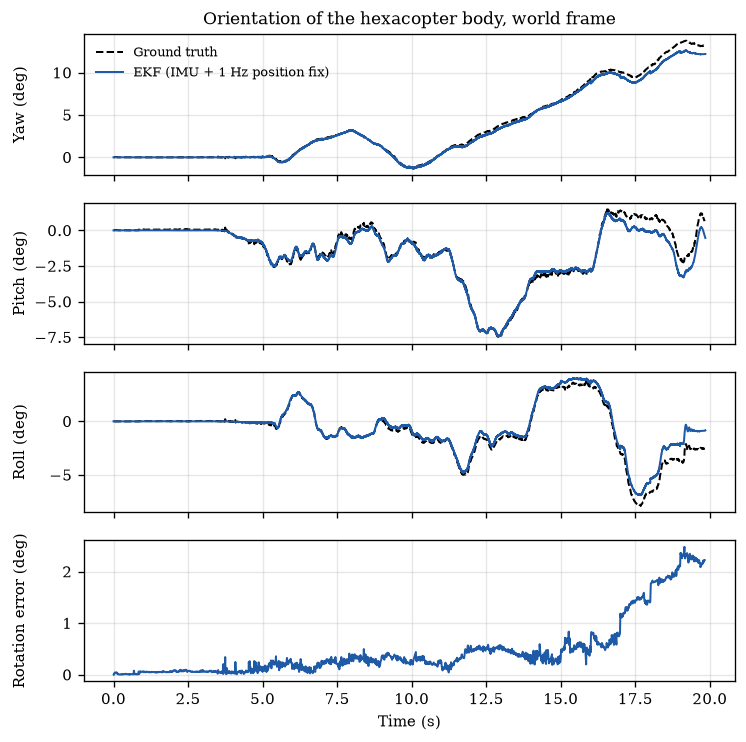

In [9]:
ground_truth_ypr = evaluation.body_euler_degrees(ground_truth_rotations, imu_from_body_rotation)
ekf_ypr = evaluation.body_euler_degrees(ekf_result["rotations"], imu_from_body_rotation)
figure = plots.plot_orientation(
    ground_truth_time, ground_truth_ypr,
    {"EKF (IMU + 1 Hz position fix)": (imu_time, ekf_ypr, ekf_rotation_error)},
)
figure.savefig(FIGURE_DIR / "orientation_ekf.png")
plt.show()

## Animation

The animation samples the EKF and the ground truth at 15 frames per second. Each pose is drawn as a camera frustum, the pyramid of space the camera can see. Its apex is the camera, its base is the image rectangle, and the black triangle marks the top of the image. The blue frustum and trail are the estimate, and the dashed frustum and trail are the ground truth. The frustum points about 17 degrees below the direction of flight because the DAVIS camera is mounted looking down.

In [10]:
ANIMATION_FPS = 15
ANIMATION_START = 4.0  # seconds, just before take-off

frame_times = np.arange(ANIMATION_START, ground_truth_time[-1], 1 / ANIMATION_FPS)
estimate_frames = evaluation.nearest_indices(imu_time, frame_times)
ground_truth_frames = evaluation.nearest_indices(ground_truth_time, frame_times)

# world_from_camera = world_from_imu @ imu_from_camera, so the frustum follows the lens, not the IMU axes
imu_from_camera_rotation = camera_from_imu_rotation.T
estimate_camera_rotations = ekf_result["rotations"][estimate_frames] @ imu_from_camera_rotation
ground_truth_camera_rotations = ground_truth_rotations[ground_truth_frames] @ imu_from_camera_rotation

plots.animate_flight(
    frame_times,
    ekf_result["positions"][estimate_frames],
    estimate_camera_rotations,
    ground_truth_positions[ground_truth_frames],
    ground_truth_camera_rotations,
    FIGURE_DIR / "flight_ekf.gif",
    estimate_name="EKF (IMU + 1 Hz position fix)",
    frames_per_second=ANIMATION_FPS,
)
print("saved", FIGURE_DIR / "flight_ekf.gif")

saved ../figures/flight_ekf.gif
